# Can words help a model find objects?

### Key words

| Word | Meaning | Example |
|---|---|---|
| YOLO | "You Only Look Once": a fast model that finds objects in one look at the image | `yolo26n.pt` |
| Ultralytics | The company and Python library that provide YOLO | `from ultralytics import YOLO` |
| Weights (`.pt` file) | The numbers a model learned during training, stored in a file | `yolo26n.pt` = 5.5 MB |
| Class | A type of object the model can name | `cat` |
| Box | A rectangle around a found object | A box around the cat |
| Confidence | How sure the model is, from 0 to 1 | `cat 0.91` = 91% sure |
| Threshold (`conf`) | The minimum confidence to keep an answer | `conf=0.25` keeps answers of 25% or more |
| Segmentation / mask | The exact shape of an object, pixel by pixel | The cat's outline, coloured |
| Prompt | The words given to the model | `["cat", "flower"]` |
| Vector | A list of numbers that stands for a word | `"cat"` → `[0.12, -0.40, ...]` |
| Open vocabulary | The list of objects is chosen when the model is used | YOLOE with any words |
| mAP | The standard score for detection, from 0 to 1 (higher is better). Not used here: it needs photos labelled by hand | `mAP = 0.40` |
| RGB / BGR | The order of the 3 colours: red-green-blue or blue-green-red | `[:, :, ::-1]` swaps the order |

## 0. Setup
Run this cell once. Expected output: `True`. If it shows `False` or an error, select the `.venv` kernel (top right).

In [1]:
import sys
print("Using this folder's uv environment:", ".venv" in sys.executable)

# Tools
import os
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO, YOLOE

# The two photos
IMAGES = ["example1.jpeg", "example2.jpeg"]


# Helper: draw each photo with its boxes, then list what was found (example: "cat 0.91")
def show(results):
    for r in results:
        plt.figure(figsize=(5, 6))
        plt.imshow(r.plot()[:, :, ::-1])  # [:, :, ::-1] fixes the colours
        plt.title(os.path.basename(r.path))
        plt.axis("off")
        plt.show()
        for box in r.boxes:
            name = r.names[int(box.cls.item())]
            confidence = round(box.conf.item(), 2)
            print(name, confidence)


# Helper: two models side by side, one row per photo (boxes / masks can be switched off)
def side_by_side(left, right, titles, boxes=True, masks=True):
    for a, b in zip(left, right):
        fig, axes = plt.subplots(1, 2, figsize=(10, 6))
        for ax, r, title in zip(axes, [a, b], titles):
            ax.imshow(r.plot(boxes=boxes, masks=masks)[:, :, ::-1])
            ax.set_title(f"{title}\n{os.path.basename(r.path)}")
            ax.axis("off")
        plt.show()

Using this folder's uv environment: True


## 1. Look at the photos

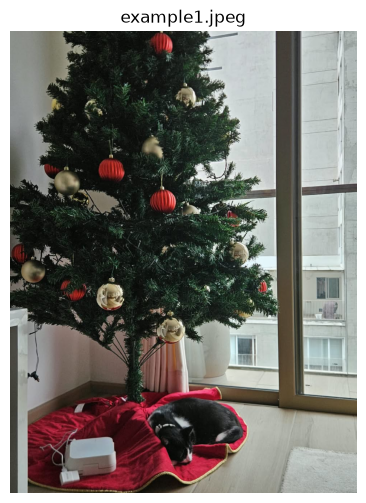

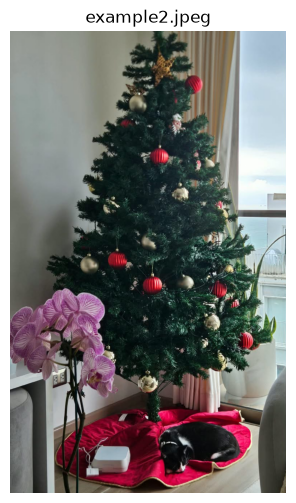

In [2]:
for image in IMAGES:
    plt.figure(figsize=(5, 6))
    plt.imshow(plt.imread(image))
    plt.title(image)
    plt.axis("off")
    plt.show()

**What to observe:** both photos contain a christmas tree and a cat. Only `example2.jpeg` contains a flower (a pink orchid).

## 2. A standard model (YOLO26n)

It recognises only the objects in its fixed list of 80.
Example: "cat" is on the list. "christmas tree" is not.

In [3]:
yolo = YOLO("yolo26n.pt")

print("Knows 'cat'?", "cat" in yolo.names.values())
print("Knows 'christmas tree'?", "christmas tree" in yolo.names.values())
print("Knows 'flower'?", "flower" in yolo.names.values())
print()
print("Its full list:", list(yolo.names.values()))

Knows 'cat'? True
Knows 'christmas tree'? False
Knows 'flower'? False

Its full list: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


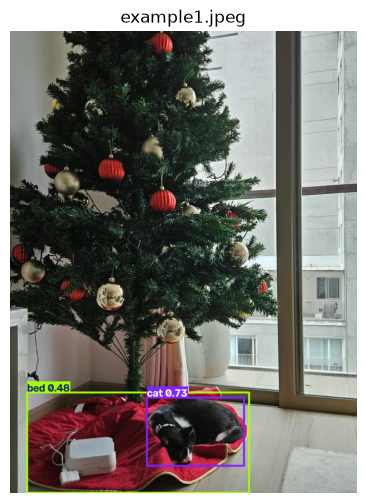

cat 0.73
bed 0.48


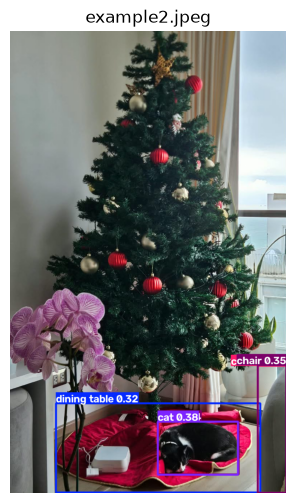

cat 0.38
chair 0.35
couch 0.34
dog 0.34
dining table 0.32


In [4]:
results = yolo(IMAGES, verbose=False)  # verbose=False hides technical messages
show(results)

## 3. A model that reads words (YOLOE-26n)

### What is YOLOE?
YOLOE comes from the paper *"YOLOE: Real-Time Seeing Anything"* (2025). It is a YOLO model with an **open vocabulary**.

| | Closed vocabulary (YOLO26n) | Open vocabulary (YOLOE) |
|---|---|---|
| Objects it can find | A fixed list of 80, set during training | Any words, chosen when the model is used |
| Adding a new object | New labelled images and new training | A new word |

**How it works**
1. A small text model (MobileCLIP) turns each word into a vector of 512 numbers. Similar words give similar vectors.
2. The image network turns each region of the photo into a vector of the same size.
3. Each region is compared with each word. A close match gives a box with that word.

In [5]:
yoloe = YOLOE("yoloe-26n-seg.pt")

# Inside the model: the word "cat" as numbers
numbers = yoloe.get_text_pe(["cat"]).flatten()
print("'cat' becomes", len(numbers), "numbers. The first five:", numbers[:5])

c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


'cat' becomes 512 numbers. The first five: tensor([-0.0022,  0.0147,  0.0646,  0.0086, -0.0301])


Now it looks for: ['christmas tree', 'cat', 'flower']


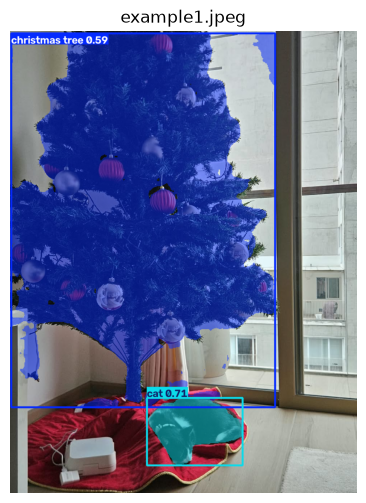

cat 0.71
christmas tree 0.59


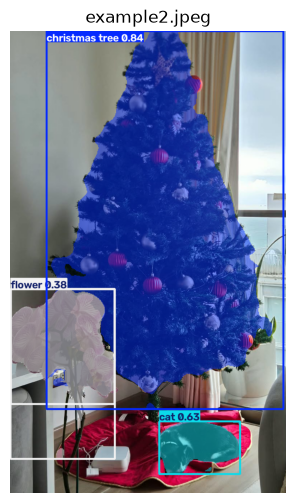

christmas tree 0.84
cat 0.63
flower 0.38
flower 0.31


In [6]:
words = ["christmas tree", "cat", "flower"]
yoloe.set_classes(words)  # these words become the list of objects to find
print("Now it looks for:", list(yoloe.names.values()))

results = yoloe(IMAGES, verbose=False)
show(results)

## 4. Prompt quality
Same model and photos; only the words change. Each prompt is tested alone, and the table shows its highest confidence in each photo.

| Type | Example |
|---|---|
| specific | `christmas tree` |
| generic | `tree` |
| sentence | `a decorated christmas tree with red and gold balls` |
| typo | `chrismas tre` |
| wrong (not in the photo) | `palm tree` |

In [7]:
TESTS = [  # (object, type, prompt)
    ("tree", "specific", "christmas tree"),
    ("tree", "generic", "tree"),
    ("tree", "sentence", "a decorated christmas tree with red and gold balls"),
    ("tree", "typo", "chrismas tre"),
    ("tree", "wrong", "palm tree"),
    ("cat", "specific", "black and white cat"),
    ("cat", "generic", "animal"),
    ("cat", "sentence", "a black and white cat sleeping on a red blanket"),
    ("cat", "typo", "catt"),
    ("cat", "wrong", "dog"),
    ("flower", "specific", "pink orchid"),
    ("flower", "generic", "flower"),
    ("flower", "sentence", "pink orchid flowers in a pot"),
    ("flower", "typo", "orkid"),
    ("flower", "wrong", "sunflower"),
]


# Highest confidence in one photo (0 if nothing was found)
def best_score(result):
    if len(result.boxes) == 0:
        return 0.0
    return round(result.boxes.conf.max().item(), 2)


rows = []
for obj, kind, prompt in TESTS:
    yoloe.set_classes([prompt])  # search for this prompt only
    photo1, photo2 = yoloe(IMAGES, conf=0.01, verbose=False)  # conf=0.01 keeps low-confidence answers
    rows.append([obj, kind, prompt, best_score(photo1), best_score(photo2)])

scores = pd.DataFrame(rows, columns=["object", "type", "prompt", "example1", "example2"])
scores

,object,type,prompt,example1,example2
0,tree,specific,christmas tree,0.59,0.84
1,tree,generic,tree,0.28,0.08
2,tree,sentence,a decorated christmas tree with red and gold b...,0.49,0.68
3,tree,typo,chrismas tre,0.09,0.39
4,tree,wrong,palm tree,0.00,0.00
5,cat,specific,black and white cat,0.55,0.43
6,cat,generic,animal,0.49,0.29
7,cat,sentence,a black and white cat sleeping on a red blanket,0.45,0.49
8,cat,typo,catt,0.25,0.30
9,cat,wrong,dog,0.69,0.59


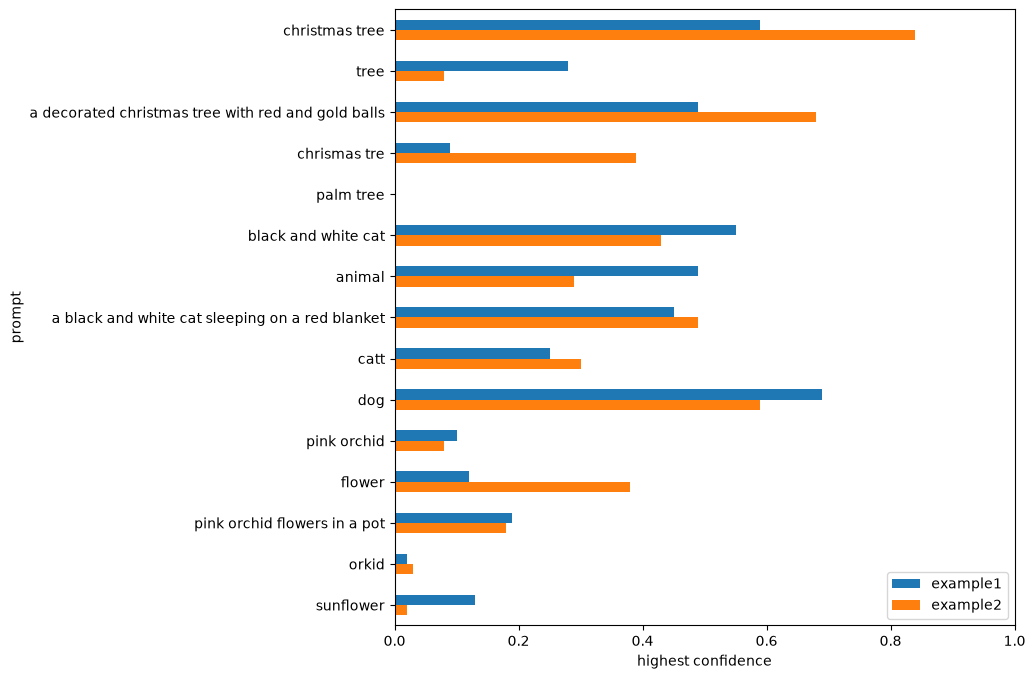

In [8]:
scores.plot.barh(x="prompt", y=["example1", "example2"], figsize=(8, 8), xlim=(0, 1))
plt.gca().invert_yaxis()  # same order as the table
plt.xlabel("highest confidence")
plt.show()

---
## 5. Detection only (boxes)
Detection draws a **rectangle** around each object. It returns a name, a confidence and 4 numbers: the box corners.

Left: YOLO26n (fixed list of 80). Right: YOLOE (words `christmas tree`, `cat`, `flower`).

In [9]:
# 5.1 Run both models
det_words = ["christmas tree", "cat", "flower"]
yoloe.set_classes(det_words)

det_yolo = yolo(IMAGES, verbose=False)
det_yoloe = yoloe(IMAGES, verbose=False)

c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [10]:
# 5.2 Inspect one result: the content of a detection (YOLO26n, example1)
r = det_yolo[0]
for box in r.boxes:
    name = r.names[int(box.cls.item())]
    confidence = round(box.conf.item(), 2)
    corners = [round(v) for v in box.xyxy[0].tolist()]
    print(name, confidence, "box (left, top, right, bottom):", corners)

cat 0.73 box (left, top, right, bottom): [379, 1016, 648, 1204]
bed 0.48 box (left, top, right, bottom): [48, 1001, 663, 1280]


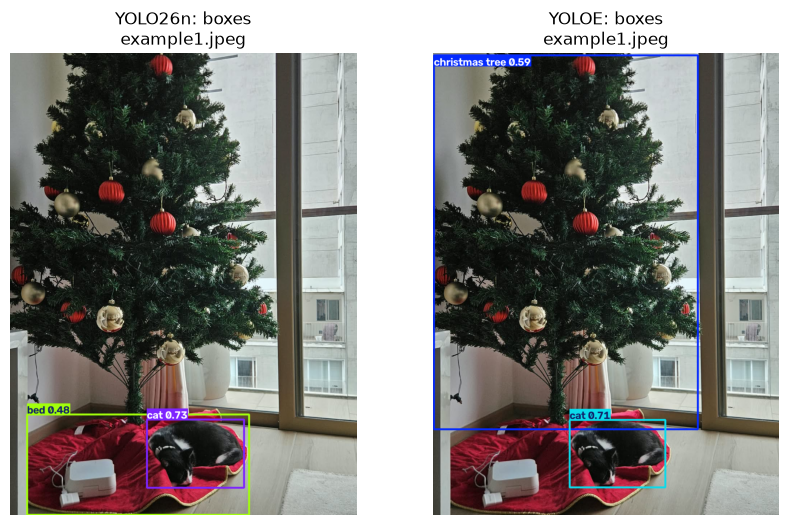

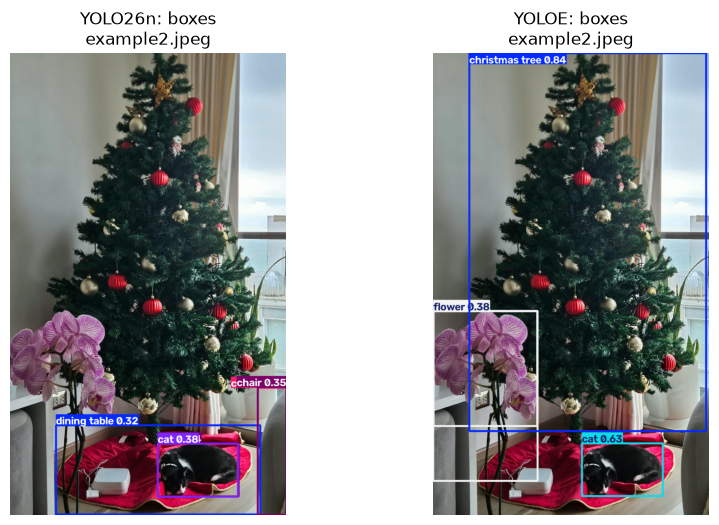

In [11]:
# 5.3 Side by side: boxes only
side_by_side(det_yolo, det_yoloe, ["YOLO26n: boxes", "YOLOE: boxes"], masks=False)

In [12]:
# 5.4 Table: what each model found
rows = []
for model, results in [("YOLO26n", det_yolo), ("YOLOE", det_yoloe)]:
    for r in results:
        for box in r.boxes:
            rows.append([model, os.path.basename(r.path), r.names[int(box.cls.item())], round(box.conf.item(), 2)])

pd.DataFrame(rows, columns=["model", "photo", "object", "confidence"])

,model,photo,object,confidence
0,YOLO26n,example1.jpeg,cat,0.73
1,YOLO26n,example1.jpeg,bed,0.48
2,YOLO26n,example2.jpeg,cat,0.38
3,YOLO26n,example2.jpeg,chair,0.35
4,YOLO26n,example2.jpeg,couch,0.34
5,YOLO26n,example2.jpeg,dog,0.34
6,YOLO26n,example2.jpeg,dining table,0.32
7,YOLOE,example1.jpeg,cat,0.71
8,YOLOE,example1.jpeg,christmas tree,0.59
9,YOLOE,example2.jpeg,christmas tree,0.84


---
## 6. Segmentation only (shapes)
Segmentation colours the **exact pixels** of each object. It returns a name, a confidence and a mask: a grid with 1 on the object and 0 elsewhere.

Left: YOLO26n-seg (fixed list of 80, 6.7 MB download). Right: YOLOE (same words). Without boxes, the names appear in the table.

In [13]:
# 6.1 Run both models
yolo_seg = YOLO("yolo26n-seg.pt")

seg_words = ["christmas tree", "cat", "flower"]
yoloe.set_classes(seg_words)

seg_yolo = yolo_seg(IMAGES, retina_masks=True, verbose=False)  # retina_masks: masks at full photo size
seg_yoloe = yoloe(IMAGES, retina_masks=True, verbose=False)

Object: dog
Mask size (rows, columns): (1280, 960)
Share of the photo: 3%


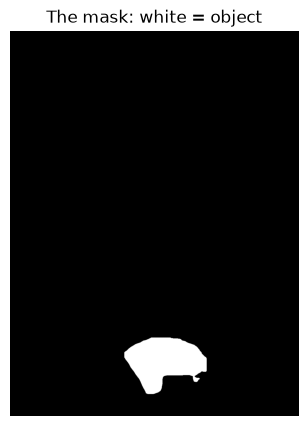

In [14]:
# 6.2 Inspect one result: the content of a mask (YOLO26n-seg, example1, first object)
r = seg_yolo[0]
mask = r.masks.data[0]

print("Object:", r.names[int(r.boxes.cls[0].item())])
print("Mask size (rows, columns):", tuple(mask.shape))
print("Share of the photo:", f"{mask.float().mean().item():.0%}")

plt.figure(figsize=(4, 5))
plt.imshow(mask, cmap="gray")  # white = 1 (object), black = 0 (not object)
plt.title("The mask: white = object")
plt.axis("off")
plt.show()

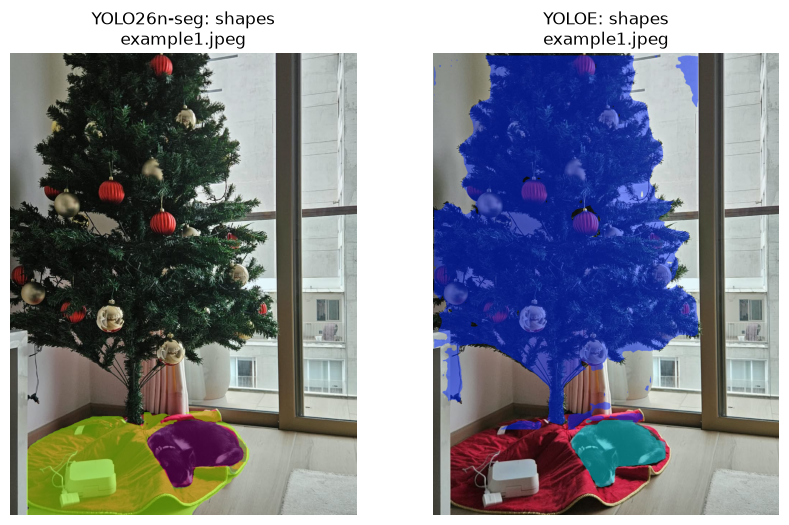

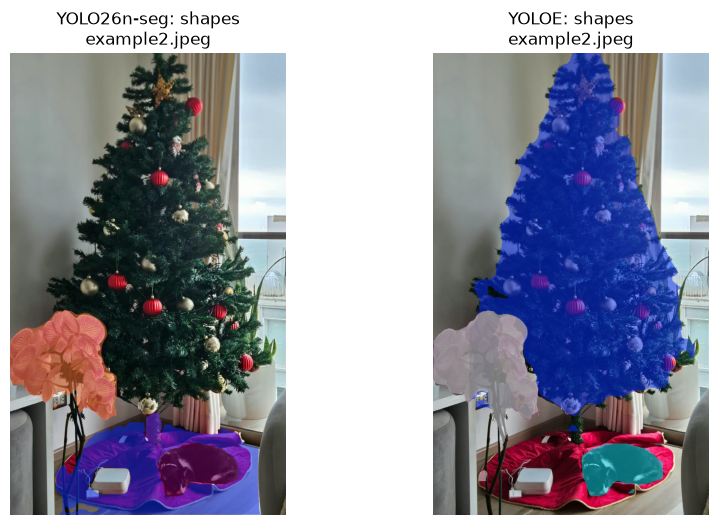

In [15]:
# 6.3 Side by side: shapes only
side_by_side(seg_yolo, seg_yoloe, ["YOLO26n-seg: shapes", "YOLOE: shapes"], boxes=False)

In [16]:
# 6.4 Table: what each model found, and how much of the photo it covers
rows = []
for model, results in [("YOLO26n-seg", seg_yolo), ("YOLOE", seg_yoloe)]:
    for r in results:
        for i, box in enumerate(r.boxes):
            share = f"{r.masks.data[i].float().mean().item():.0%}"
            rows.append([model, os.path.basename(r.path), r.names[int(box.cls.item())], round(box.conf.item(), 2), share])

pd.DataFrame(rows, columns=["model", "photo", "object", "confidence", "share of photo"])

,model,photo,object,confidence,share of photo
0,YOLO26n-seg,example1.jpeg,dog,0.74,3%
1,YOLO26n-seg,example1.jpeg,bed,0.68,9%
2,YOLO26n-seg,example2.jpeg,vase,0.37,0%
3,YOLO26n-seg,example2.jpeg,dog,0.37,2%
4,YOLO26n-seg,example2.jpeg,dining table,0.30,9%
5,YOLO26n-seg,example2.jpeg,potted plant,0.28,6%
6,YOLOE,example1.jpeg,cat,0.71,2%
7,YOLOE,example1.jpeg,christmas tree,0.59,41%
8,YOLOE,example2.jpeg,christmas tree,0.84,37%
9,YOLOE,example2.jpeg,cat,0.63,2%


---

## 7. Experiments with other words
Change the words and run the cell again.

c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


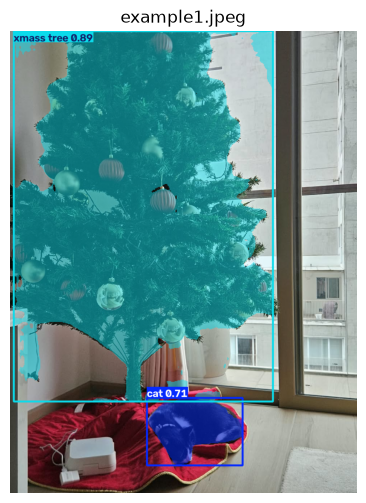

xmass tree 0.89
cat 0.71


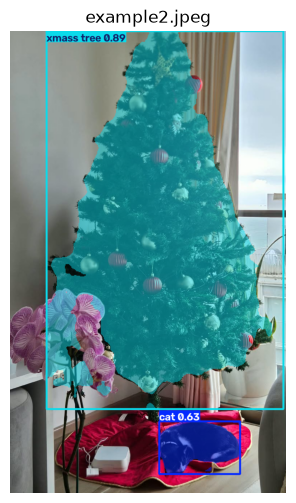

xmass tree 0.89
cat 0.63


In [17]:
yoloe.set_classes(["cat", "xmass tree", "tree"])
results = yoloe(IMAGES, verbose=False)
show(results)

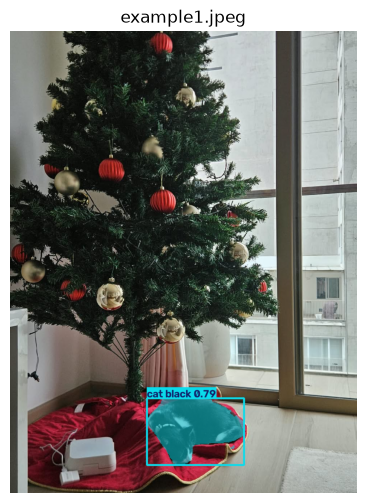

cat black 0.79


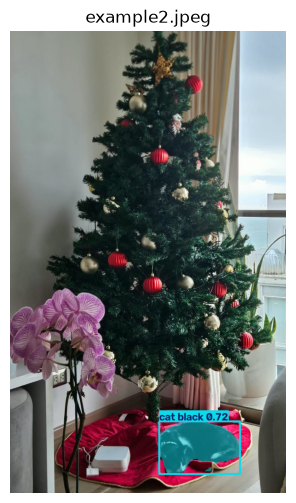

cat black 0.72


In [18]:
yoloe.set_classes(["cat", "cat black", "cat sleeping"])
results = yoloe(IMAGES, verbose=False)
show(results)

## 8. Unusual images: pages about the Hubble telescope
Five pages with objects that are not in the fixed list of 80, such as solar panels and satellites.

`imgsz=1280` makes the model look at a larger image, so small details are kept. With the default size (640), most of these objects are missed.

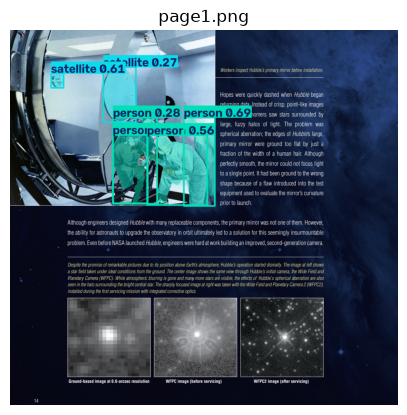

person 0.69
satellite 0.61
person 0.56
person 0.42
person 0.28
satellite 0.27


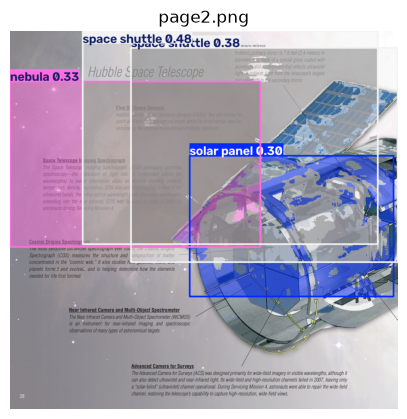

space shuttle 0.48
space shuttle 0.38
nebula 0.33
solar panel 0.3


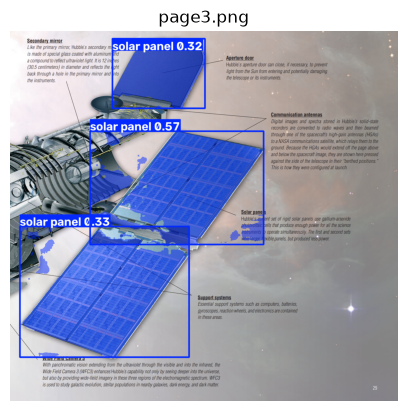

solar panel 0.57
solar panel 0.33
solar panel 0.32


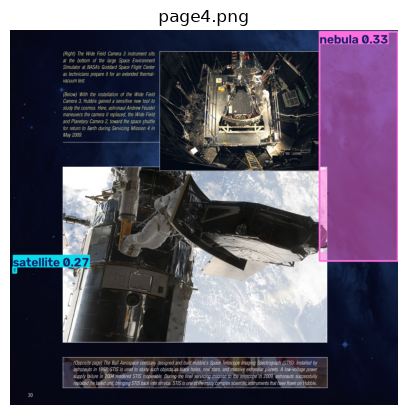

nebula 0.33
satellite 0.27


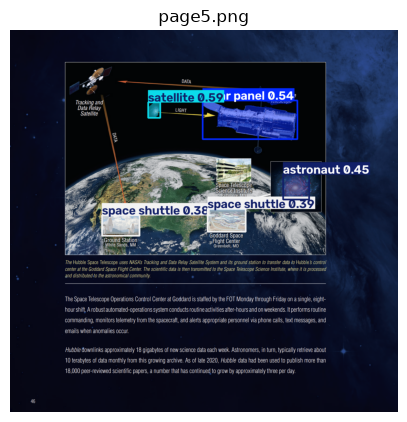

satellite 0.59
solar panel 0.54
astronaut 0.45
space shuttle 0.39
space shuttle 0.38


In [19]:
PAGES = ["page1.png", "page2.png", "page3.png", "page4.png", "page5.png"]

yoloe.set_classes(["solar panel", "satellite", "space shuttle", "person", "astronaut", "nebula"])
results = yoloe(PAGES, imgsz=1280, verbose=False)
show(results)